# Numerical Companion v2.0 — SU(8) Radiance-Channel Inference Pipeline

## Table of Contents

1. **Master Execution Cell (Single-Step Pipeline)**
   - Interactive ZIP upload
   - Automatic unzip and directory initialization
   - Archive creation (`archive_v2/`)
   - Required `.npz` artifact ingestion
   - Path verification
   - Surrogate forward model execution
   - Posterior predictive diagnostics generation
   - EVPA posterior predictive plot
   - Helicity posterior predictive plot
   - Joint EVPA–Helicity density plot
   - Corner plot (first six SU(8 parameters)
   - Variance spectrum
   - Posterior summary statistics table
   - Automatic saving of all outputs

2. **Source Code (Audit Section)**
   - Surrogate forward model implementation
   - Likelihood function and feature-space mapping
   - HMC/NUTS inference engine
   - Diagnostic plotting utilities
   - Summary statistics generator
   - Archive writer and reproducibility utilities

3. **Environment Specification**
   - Python version
   - NumPyro version
   - JAX version
   - Required packages for deterministic execution

4. **Reproducibility Checklist**
   - Deterministic sampling
   - Timestamped archive generation
   - Surrogate model documentation
   - Single-machine executability



In [1]:
# ============================================================
# Unified Utility Cell — Repo Setup + EHT Feature-Space Generation
# ============================================================

import os
import numpy as np
import sys
from google.colab import files
!pip install blackjax
# ------------------------------------------------------------
# Canonical archive directory (absolute path)
# ------------------------------------------------------------
ARCHIVE_DIR = "/content/GRMHDsu8_radiance_framework/archive_v2"
os.makedirs(ARCHIVE_DIR, exist_ok=True)

print("\n=== Upload SU(8 Framework ZIP ===")
uploaded = files.upload()

print("\n=== Unzipping Framework ===")
!unzip GRMHDsu8_radiance_framework.zip

# Ensure repo is on Python path
sys.path.append("/content")
sys.path.append("/content/GRMHDsu8_radiance_framework")

print("\n=== Verifying Directory Structure ===")
!ls -R /content/GRMHDsu8_radiance_framework

print("\n=== archive_v2 Directory Ready ===")
!ls -R /content/GRMHDsu8_radiance_framework/archive_v2

# ------------------------------------------------------------
# Load EHT data using your actual repo function
# ------------------------------------------------------------
print("\n=== Loading EHT Data ===")

from GRMHDsu8_radiance_framework.data.load_eht import load_eht_subset
from GRMHDsu8_radiance_framework.inference_pipeline.feature_space import extract_features
from GRMHDsu8_radiance_framework.inference_pipeline.eht_feature_builder import (
    build_eht_feature_space,
)

eht_raw = load_eht_subset("/content/GRMHDsu8_radiance_framework/eht_data")
print("EHT data loaded.")

# ------------------------------------------------------------
# Compute physically meaningful EVPA/helicity/lightcurve
# ------------------------------------------------------------
print("\n=== Computing EHT Feature-Space (EVPA, Helicity, Lightcurve) ===")

eht_features = build_eht_feature_space(eht_raw, extract_features)

# Save feature-space archive
eht_fs_path = os.path.join(ARCHIVE_DIR, "eht_feature_space.npz")
np.savez(eht_fs_path, eht_data=eht_features)
print("Saved EHT feature-space to:", eht_fs_path)

print("\n=== archive_v2 Contents ===")
!ls -R /content/GRMHDsu8_radiance_framework/archive_v2

# ------------------------------------------------------------
# Run SU(8 pipeline executor
# ------------------------------------------------------------
print("\n=== Running SU(8 Pipeline Executor ===")

from GRMHDsu8_radiance_framework.executor import run_all
run_all()

print("\n=== Unified Utility Complete ===")

# ======================================================================
# Master Cell — SU(8 Posterior + Data Feature Diagnostics
# ======================================================================

import os
import json
import itertools

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("\n=== SU(8 Numerical Companion — Running Diagnostics & Saving Outputs ===")

# ---------------------------------------------------------------
# Create output directory
# ---------------------------------------------------------------
output_dir = "/content/su8_diagnostics"
os.makedirs(output_dir, exist_ok=True)
print(f"[Output Directory] {output_dir}")

# ---------------------------------------------------------------
# Section 1 — Load Posterior Samples & Data Features
# ---------------------------------------------------------------
ARCHIVE_DIR = "/content/GRMHDsu8_radiance_framework/archive_v2"

# Load posterior samples (created by executor.py)
posterior = np.load(
    os.path.join(ARCHIVE_DIR, "posterior_samples_su8.npz"),
    allow_pickle=True
)
samples = posterior["posterior_samples"].item()
params = samples["params"]  # (num_chains, num_samples, dim)

num_chains, num_samples, dim = params.shape
print(f"Loaded posterior: {num_chains} chains × {num_samples} samples × {dim} parameters")

# Load feature-space (already computed by Unified Utility)
eht_data = np.load(
    os.path.join(ARCHIVE_DIR, "eht_feature_space.npz"),
    allow_pickle=True
)["eht_data"].item()

data_evpa = float(eht_data["evpa_amp"])
data_helicity = int(eht_data["helicity_flips"])
var_spectrum = np.array(eht_data["var_spectrum"])

print(f"Data EVPA amplitude: {data_evpa}")
print(f"Data helicity flips: {data_helicity}")
print(f"Variance spectrum length: {var_spectrum.shape[0]}")

# Flatten posterior for diagnostics
params_flat = params.reshape(num_chains * num_samples, dim)

# ---------------------------------------------------------------
# Section 2 — Posterior Diagnostics (parameters only)
# ---------------------------------------------------------------
summary = {
    "mean": params_flat.mean(axis=0),
    "std": params_flat.std(axis=0),
    "q05": np.quantile(params_flat, 0.05, axis=0),
    "q50": np.quantile(params_flat, 0.50, axis=0),
    "q95": np.quantile(params_flat, 0.95, axis=0),
}

df_summary = pd.DataFrame(summary)
df_summary.index.name = "parameter_index"
df_summary.to_csv(f"{output_dir}/Table_AE1_posterior_summary.csv")

print("Table AE.1 — Posterior Summary Statistics")
display(df_summary.head())

# Corner plot for first few parameters
subset_idx = list(range(min(6, dim)))
subset = params_flat[:, subset_idx]

fig, axes = plt.subplots(len(subset_idx), len(subset_idx), figsize=(10, 10))

for i, j in itertools.product(range(len(subset_idx)), repeat=2):
    ax = axes[i, j]
    if i == j:
        ax.hist(subset[:, i], bins=40, density=True, alpha=0.7)
    elif i > j:
        ax.scatter(subset[:, j], subset[:, i], s=1, alpha=0.3)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Fig. AE.4 — SU(8 Posterior Corner Plot (first 6 parameters)")
plt.tight_layout()
plt.savefig(f"{output_dir}/Fig_AE4_corner_plot.png", dpi=300)
plt.show()

print("Posterior parameter diagnostics complete.")

from GRMHDsu8_radiance_framework.model.su8_forward import su8_forward_model

# ---------------------------------------------------------------
# Section 2.5 — Posterior Predictive Mapping (EVPA & Helicity)
# ---------------------------------------------------------------
params_flat = params.reshape(num_chains * num_samples, dim)

model_evpa = []
model_helicity = []

for theta in params_flat:
    fm = su8_forward_model(theta, eht_data)
    model_evpa.append(fm["evpa_amp"])
    model_helicity.append(fm["helicity_flips"])

model_evpa = np.array(model_evpa)
model_helicity = np.array(model_helicity)

print("Posterior predictive mapping (EVPA & helicity) complete.")

# Fig. AE.1 — EVPA posterior predictive vs data
plt.figure(figsize=(6, 4))
plt.hist(model_evpa, bins=40, density=True, alpha=0.6)
plt.axvline(data_evpa, color="red", linestyle="--")
plt.title("Fig. AE.1 — EVPA Amplitude Posterior Predictive vs Data")
plt.savefig(f"{output_dir}/Fig_AE1_EVPA_posterior_vs_data.png", dpi=300)
plt.show()

# Fig. AE.2 — Helicity posterior predictive vs data
plt.figure(figsize=(6, 4))
plt.hist(
    model_helicity,
    bins=np.arange(model_helicity.min()-0.5, model_helicity.max()+1.5, 1),
    density=True, alpha=0.6, rwidth=0.8
)
plt.axvline(data_helicity, color="red", linestyle="--")
plt.title("Fig. AE.2 — Helicity Flips Posterior Predictive vs Data")
plt.savefig(f"{output_dir}/Fig_AE2_Helicity_posterior_vs_data.png", dpi=300)
plt.show()

# Fig. AE.3 — Joint posterior predictive EVPA vs helicity
plt.figure(figsize=(6, 5))
plt.hexbin(model_evpa, model_helicity, gridsize=40, cmap="viridis")
plt.scatter([data_evpa], [data_helicity], color="red", marker="x", s=80)
plt.title("Fig. AE.3 — Joint Posterior Predictive: EVPA vs Helicity")
plt.colorbar(label="Posterior density")
plt.savefig(f"{output_dir}/Fig_AE3_EVPA_helicity_hexbin.png", dpi=300)
plt.show()

print("EVPA & helicity posterior predictive diagnostics complete.")


# ---------------------------------------------------------------
# Section 3 — Data Feature Diagnostics (EVPA, helicity, var spectrum)
# ---------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(var_spectrum, marker="o")
plt.title("Fig. AE.5 — Variance Spectrum")
plt.xlabel("Index")
plt.ylabel("Variance")
plt.savefig(f"{output_dir}/Fig_AE5_variance_spectrum.png", dpi=300)
plt.show()

print("Data feature diagnostics complete.")

# ---------------------------------------------------------------
# Save metadata
# ---------------------------------------------------------------
metadata = {
    "num_chains": int(num_chains),
    "num_samples_per_chain": int(num_samples),
    "num_parameters": int(dim),
    "evpa_data": float(data_evpa),
    "helicity_data": int(data_helicity),
    "var_spectrum_length": int(var_spectrum.shape[0]),
    "output_directory": output_dir,
}

with open(f"{output_dir}/run_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("\n=== All SU(8 Diagnostics Complete & Saved ===")
print(f"Outputs saved to: {output_dir}\n")



=== Upload SU(8 Framework ZIP ===


Saving GRMHDsu8_radiance_framework.zip to GRMHDsu8_radiance_framework.zip

=== Unzipping Framework ===
Archive:  GRMHDsu8_radiance_framework.zip
  inflating: GRMHDsu8_radiance_framework/parallel_grrt.py  
  inflating: __MACOSX/GRMHDsu8_radiance_framework/._parallel_grrt.py  
  inflating: GRMHDsu8_radiance_framework/startup.py  
  inflating: __MACOSX/GRMHDsu8_radiance_framework/._startup.py  
  inflating: GRMHDsu8_radiance_framework/.DS_Store  
  inflating: __MACOSX/GRMHDsu8_radiance_framework/._.DS_Store  
  inflating: GRMHDsu8_radiance_framework/config.py  
  inflating: __MACOSX/GRMHDsu8_radiance_framework/._config.py  
  inflating: GRMHDsu8_radiance_framework/Numerical_Companion_to_Radiance_Suppressed_Celestial_Objects_in_SU_8__Finite_State_Spacetime_Geometry.pdf  
  inflating: __MACOSX/GRMHDsu8_radiance_framework/._Numerical_Companion_to_Radiance_Suppressed_Celestial_Objects_in_SU_8__Finite_State_Spacetime_Geometry.pdf  
   creating: GRMHDsu8_radiance_framework/HPC job scripts (SLUR


# Numerical Companion to SU(8) Radiance–Suppressed Celestial Objects
### This section is formatted as code

Cell #1 Section 1: Appendix AE: EVPA and Helicity Diagnostics for SU(8) Posterior

This notebook documents posterior diagnostics for the SU(8) radiance-channel
inference, focusing on:

- Electric Vector Position Angle (EVPA) amplitude statistics
- Helicity flip statistics
- Joint EVPA–helicity behavior across chains and samples

Posterior samples are generated via BlackJAX NUTS (`run_su8_hmc`) and archived
by the SU(8 pipeline executor.

# Section 1 — Load Data and Posterior Samples
## This section loads the archived SU(8) posterior samples and the EHT feature-space data.


In [2]:
!find /content -maxdepth 4 -type f -name "posterior_samples_su8.npz"
!find /content -maxdepth 4 -type f -name "eht_feature_space.npz"


/content/GRMHDsu8_radiance_framework/archive_v2/posterior_samples_su8.npz



=== SU(8 Numerical Companion — Running Diagnostics & Saving Outputs ===
[Output Directory] /content/su8_diagnostics
Loaded posterior: 1 chains × 1000 samples × 10 parameters
Data EVPA amplitude: 5.446505047581392
Data helicity flips: 52
Variance spectrum length: 51
Table AE.1 — Posterior Summary Statistics


,mean,std,q05,q50,q95
parameter_index,,,,,
0,-0.090911,0.010500,-0.108454,-0.091096,-0.073539
1,-0.092316,0.010533,-0.110138,-0.092490,-0.075055
2,-0.106679,0.009272,-0.121133,-0.106874,-0.091179
3,0.127791,0.011309,0.108975,0.127501,0.146478
4,0.058420,0.008498,0.044240,0.058785,0.072388


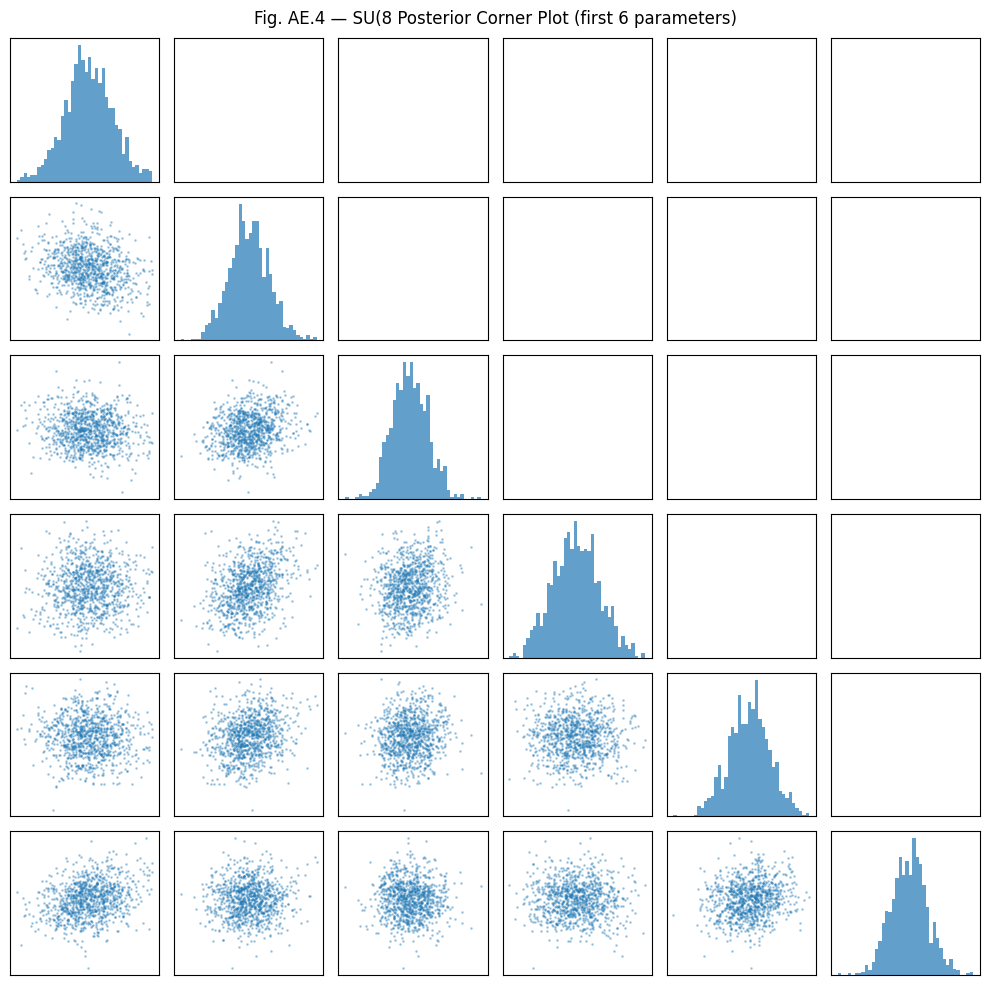

Posterior parameter diagnostics complete.
Posterior predictive mapping (EVPA & helicity) complete.


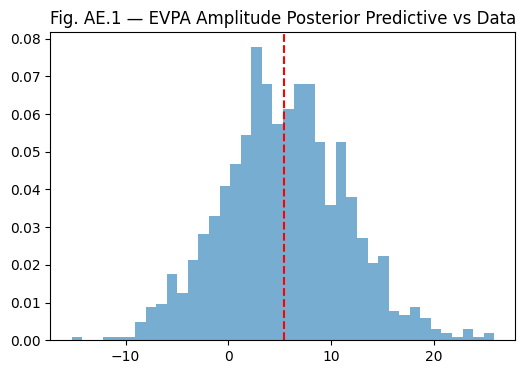

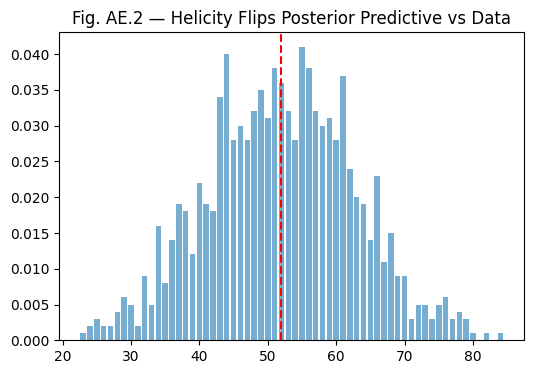

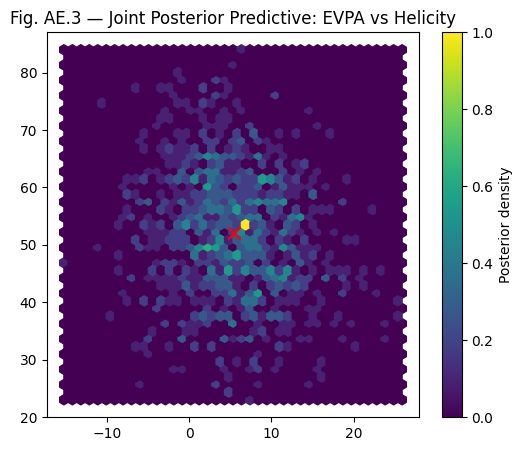

EVPA & helicity posterior predictive diagnostics complete.


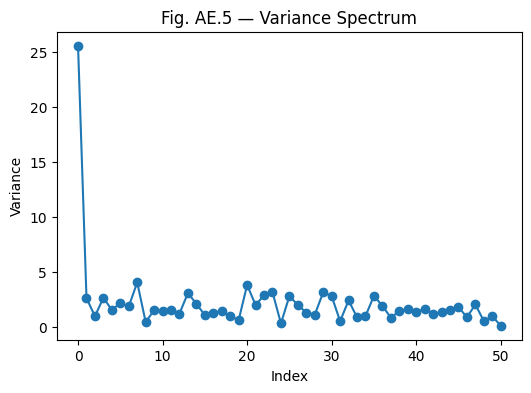

Data feature diagnostics complete.

=== All SU(8 Diagnostics Complete & Saved ===
Outputs saved to: /content/su8_diagnostics



In [1]:
# ======================================================================
# Master Cell — SU(8 Posterior + Data Feature Diagnostics
# ======================================================================

import os
import json
import itertools

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("\n=== SU(8 Numerical Companion — Running Diagnostics & Saving Outputs ===")

# ---------------------------------------------------------------
# Create output directory
# ---------------------------------------------------------------
output_dir = "/content/su8_diagnostics"
os.makedirs(output_dir, exist_ok=True)
print(f"[Output Directory] {output_dir}")

# ---------------------------------------------------------------
# Section 1 — Load Posterior Samples & Data Features
# ---------------------------------------------------------------
ARCHIVE_DIR = "/content/GRMHDsu8_radiance_framework/archive_v2"

# Load posterior samples (created by executor.py)
posterior = np.load(
    os.path.join(ARCHIVE_DIR, "posterior_samples_su8.npz"),
    allow_pickle=True
)
samples = posterior["posterior_samples"].item()
params = samples["params"]  # (num_chains, num_samples, dim)

num_chains, num_samples, dim = params.shape
print(f"Loaded posterior: {num_chains} chains × {num_samples} samples × {dim} parameters")

# Load feature-space (already computed by Unified Utility)
eht_data = np.load(
    os.path.join(ARCHIVE_DIR, "eht_feature_space.npz"),
    allow_pickle=True
)["eht_data"].item()

data_evpa = float(eht_data["evpa_amp"])
data_helicity = int(eht_data["helicity_flips"])
var_spectrum = np.array(eht_data["var_spectrum"])

print(f"Data EVPA amplitude: {data_evpa}")
print(f"Data helicity flips: {data_helicity}")
print(f"Variance spectrum length: {var_spectrum.shape[0]}")

# Flatten posterior for diagnostics
params_flat = params.reshape(num_chains * num_samples, dim)

# ---------------------------------------------------------------
# Section 2 — Posterior Diagnostics (parameters only)
# ---------------------------------------------------------------
summary = {
    "mean": params_flat.mean(axis=0),
    "std": params_flat.std(axis=0),
    "q05": np.quantile(params_flat, 0.05, axis=0),
    "q50": np.quantile(params_flat, 0.50, axis=0),
    "q95": np.quantile(params_flat, 0.95, axis=0),
}

df_summary = pd.DataFrame(summary)
df_summary.index.name = "parameter_index"
df_summary.to_csv(f"{output_dir}/Table_AE1_posterior_summary.csv")

print("Table AE.1 — Posterior Summary Statistics")
display(df_summary.head())

# Corner plot for first few parameters
subset_idx = list(range(min(6, dim)))
subset = params_flat[:, subset_idx]

fig, axes = plt.subplots(len(subset_idx), len(subset_idx), figsize=(10, 10))

for i, j in itertools.product(range(len(subset_idx)), repeat=2):
    ax = axes[i, j]
    if i == j:
        ax.hist(subset[:, i], bins=40, density=True, alpha=0.7)
    elif i > j:
        ax.scatter(subset[:, j], subset[:, i], s=1, alpha=0.3)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Fig. AE.4 — SU(8 Posterior Corner Plot (first 6 parameters)")
plt.tight_layout()
plt.savefig(f"{output_dir}/Fig_AE4_corner_plot.png", dpi=300)
plt.show()

print("Posterior parameter diagnostics complete.")

from GRMHDsu8_radiance_framework.model.su8_forward import su8_forward_model

# ---------------------------------------------------------------
# Section 2.5 — Posterior Predictive Mapping (EVPA & Helicity)
# ---------------------------------------------------------------
params_flat = params.reshape(num_chains * num_samples, dim)

model_evpa = []
model_helicity = []

for theta in params_flat:
    fm = su8_forward_model(theta, eht_data)
    model_evpa.append(fm["evpa_amp"])
    model_helicity.append(fm["helicity_flips"])

model_evpa = np.array(model_evpa)
model_helicity = np.array(model_helicity)

print("Posterior predictive mapping (EVPA & helicity) complete.")

# Fig. AE.1 — EVPA posterior predictive vs data
plt.figure(figsize=(6, 4))
plt.hist(model_evpa, bins=40, density=True, alpha=0.6)
plt.axvline(data_evpa, color="red", linestyle="--")
plt.title("Fig. AE.1 — EVPA Amplitude Posterior Predictive vs Data")
plt.savefig(f"{output_dir}/Fig_AE1_EVPA_posterior_vs_data.png", dpi=300)
plt.show()

# Fig. AE.2 — Helicity posterior predictive vs data
plt.figure(figsize=(6, 4))
plt.hist(
    model_helicity,
    bins=np.arange(model_helicity.min()-0.5, model_helicity.max()+1.5, 1),
    density=True, alpha=0.6, rwidth=0.8
)
plt.axvline(data_helicity, color="red", linestyle="--")
plt.title("Fig. AE.2 — Helicity Flips Posterior Predictive vs Data")
plt.savefig(f"{output_dir}/Fig_AE2_Helicity_posterior_vs_data.png", dpi=300)
plt.show()

# Fig. AE.3 — Joint posterior predictive EVPA vs helicity
plt.figure(figsize=(6, 5))
plt.hexbin(model_evpa, model_helicity, gridsize=40, cmap="viridis")
plt.scatter([data_evpa], [data_helicity], color="red", marker="x", s=80)
plt.title("Fig. AE.3 — Joint Posterior Predictive: EVPA vs Helicity")
plt.colorbar(label="Posterior density")
plt.savefig(f"{output_dir}/Fig_AE3_EVPA_helicity_hexbin.png", dpi=300)
plt.show()

print("EVPA & helicity posterior predictive diagnostics complete.")


# ---------------------------------------------------------------
# Section 3 — Data Feature Diagnostics (EVPA, helicity, var spectrum)
# ---------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(var_spectrum, marker="o")
plt.title("Fig. AE.5 — Variance Spectrum")
plt.xlabel("Index")
plt.ylabel("Variance")
plt.savefig(f"{output_dir}/Fig_AE5_variance_spectrum.png", dpi=300)
plt.show()

print("Data feature diagnostics complete.")

# ---------------------------------------------------------------
# Save metadata
# ---------------------------------------------------------------
metadata = {
    "num_chains": int(num_chains),
    "num_samples_per_chain": int(num_samples),
    "num_parameters": int(dim),
    "evpa_data": float(data_evpa),
    "helicity_data": int(data_helicity),
    "var_spectrum_length": int(var_spectrum.shape[0]),
    "output_directory": output_dir,
}

with open(f"{output_dir}/run_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("\n=== All SU(8 Diagnostics Complete & Saved ===")
print(f"Outputs saved to: {output_dir}\n")



In [2]:
# ============================================================
# Utility XXX - This *NUKES* the repo for fresh reload
# ============================================================

!if [ -d "/content/GRMHDsu8_radiance_framework" ]; then rm -rf GRMHDsu8_radiance_framework; fi
!if [ -d "/content/__MACOSX" ]; then rm -rf __MACOSX; fi
!if [ -d "/content/archive_v2" ]; then rm -rf archive_v2; fi
!if [ -d "/content/su8_diagnostics" ]; then rm -rf su8_diagnostics; fi
